# NB01 — TREAD-ONE training, evaluation and export

**One custom architecture • three seeds • 60 epochs • no pretrained weights.**

Use **GPU T4 ×2**, Internet ON, Kaggle secret **HF_TOKEN** with write permission to **Shanmuk4622/tyre-wear-study**.
Attach [Tire Dataset Prepared phase2](https://www.kaggle.com/datasets/shanmuk4622/tire-dataset-prepared-phase2).
No repository/dataset ZIP upload is needed in addition to that input. Run All in order, one copy of NB01 only.

The dataset is 570 images of 12 tyres; the frozen 386/81/103 split holds out only old low/high tyres. All known mid/video material is training-only. Classification is a mileage proxy. Boundaries and masks do not measure physical alignment or tread depth.

Two independent seed processes use the two T4s; seed 3 queues as a slot becomes free. Each seed runs a real-model, fresh-process resume gate before its first measured update. A failed gate prevents long training.

**Recovery:** local checkpoint after each completed optimizer update; consistent HF bundles every 30 minutes, at seed/cell completion and catchable Stop/error. Restore uses the same RUN_TAG/source/environment. Hard kernel death can lose work since the last verified upload. Watch for `HF snapshot verified` and retain the printed revision.

The exact additive maps explain class logits at the evidence layer. They do not prove physical wear reasoning or pixel-level causality; final output includes background/occlusion diagnostics and failures.


## 1. Bootstrap and secrets
Do not paste token values into cells. The embedded payload is generated from readable Phase 3 source.

In [6]:
# Install only the tested Hub/locking tools; retain Kaggle's CUDA PyTorch.
import base64, gzip, hashlib, importlib.metadata, json, os, subprocess, sys
from pathlib import Path
for package, version in [('huggingface_hub', '0.36.2'), ('filelock', '3.29.5')]:
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package+'=='+version])
from kaggle_secrets import UserSecretsClient
os.environ['HF_TOKEN'] = UserSecretsClient().get_secret('HF_TOKEN')
os.environ['HF_HUB_DISABLE_XET'] = '1'
os.environ['HF_HUB_DOWNLOAD_TIMEOUT'] = '60'
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
RUNTIME = Path('/kaggle/working/treadone_runtime')
RUNTIME.mkdir(parents=True, exist_ok=True)
payload = json.loads(gzip.decompress(base64.b64decode('...')))
for name, encoded in payload.items():
    assert Path(name).name == name
    value = base64.b64decode(encoded)
    destination = RUNTIME/name
    temporary = destination.with_suffix(destination.suffix+'.tmp')
    temporary.write_bytes(value)
    temporary.replace(destination)
bundle = json.loads((RUNTIME/'BUNDLE.json').read_text())
for name, expected in bundle['sources_sha256'].items():
    assert hashlib.sha256((RUNTIME/name).read_bytes()).hexdigest() == expected, name
print('Verified', len(bundle['sources_sha256']), 'runtime files. HF_TOKEN loaded without displaying it.')


Verified 9 runtime files. HF_TOKEN loaded without displaying it.


## 2. Configure and define the safe launcher

In [7]:
# Keep these unchanged when resuming the same experiment.
DATA_ROOT = ''  # Auto-detect VERSION.json in the attached Kaggle input.
RUN_TAG = 'treadone-r1'
TAKE_OVER = False  # True ONCE only after the older copy is stopped and has flushed.
ALLOW_SINGLE_GPU = False  # Default training expects T4 x2; no silent fallback.
WORK = Path('/kaggle/working/treadone_train')
WORK.mkdir(parents=True, exist_ok=True)
arguments = ['train', '--root', DATA_ROOT, '--work', str(WORK), '--tag', RUN_TAG]
if TAKE_OVER:
    arguments.append('--take-over')
if ALLOW_SINGLE_GPU:
    arguments.append('--allow-single-gpu')


In [8]:
import signal, time
def launch(arguments):
    process = subprocess.Popen([sys.executable, '-B', '-u', str(RUNTIME/'run.py'), *arguments],
                               stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    try:
        for line in process.stdout:
            print(line, end='', flush=True)
        status = process.wait()
    except KeyboardInterrupt:
        print('Stop requested. Wait for the checkpoint/HF flush; a second Stop or kernel kill can interrupt cleanup.', flush=True)
        process.send_signal(signal.SIGINT)
        for line in process.stdout:
            print(line, end='', flush=True)
        process.wait()
        raise
    if status:
        raise RuntimeError('Run stopped with an error. Read the retained console/checkpoint and last verified HF revision; rerun unchanged to resume.')


## 3. Execute
Stop once and wait for the verified HF flush. A server backoff or network outage may delay it.

In [9]:
launch(arguments)

Hash checked 500/2882 files
Hash checked 1000/2882 files
Hash checked 1500/2882 files
Hash checked 2000/2882 files
Hash checked 2500/2882 files
{
  "integrity": "PASS",
  "checksummed_files": 2882,
  "image_and_mask_sets": 570,
  "domains": {
    "original_photo": 418,
    "new_video_frame": 152
  },
  "conflict_pixels_explicitly_ignored": 172439,
  "source_package_ready": true,
  "training_allowed": false,
  "next_steps": [
    "Resolve exact original/video tyre identities and freeze splits",
    "Resolve label conflicts for YOLO or other trainers without ignore support",
    "Review derived geometry proposals",
    "Run the forthcoming GPU/resume preflight"
  ]
}
RUN_PREFIX = phase3/tread-one-r1/371c40c0c6aaedaf5c5970f7721a284b042494db7bb330065f6cbde8fc3a0b8c | GPUs: 2 | three seeds; one model
HF snapshot verified: c7e5c4cbe0907ef0e41e6702d3758ae006ee98f8 {}
GPU 0 seed 1 started; real-model resume gate first
GPU 1 seed 2 started; real-model resume gate first
seed 1 smoke/resume prefl

## 4. Inspect and download
These are task-specific metrics, not a single shared accuracy. The gallery uses the declared validation winner and retains errors.

Status: completed
Validation-selected export: {'epoch': 20, 'seed': 3, 'validation_utility': 0.9722130471039863}
{
  "fixed_final": {
    "balanced_accuracy_observed": {
      "mean": 0.25203252032520324,
      "population_sd": 0.19058062064603323
    },
    "human_point_mae_width_fraction": {
      "mean": 0.012954194257035853,
      "population_sd": 0.0015532368102118986
    },
    "mask_derived_box_iou": {
      "mean": 0.8846927188716812,
      "population_sd": 0.032018216386366684
    },
    "mean_two_region_dice": {
      "mean": 0.9782927915480965,
      "population_sd": 0.002358066110005676
    },
    "mean_two_region_iou": {
      "mean": 0.9577193497185602,
      "population_sd": 0.004444195476224977
    }
  },
  "selected": {
    "balanced_accuracy_observed": {
      "mean": 0.34146341463414637,
      "population_sd": 0.22420458915671018
    },
    "human_point_mae_width_fraction": {
      "mean": 0.011893679117783903,
      "population_sd": 0.0009723317256271716
    },
    

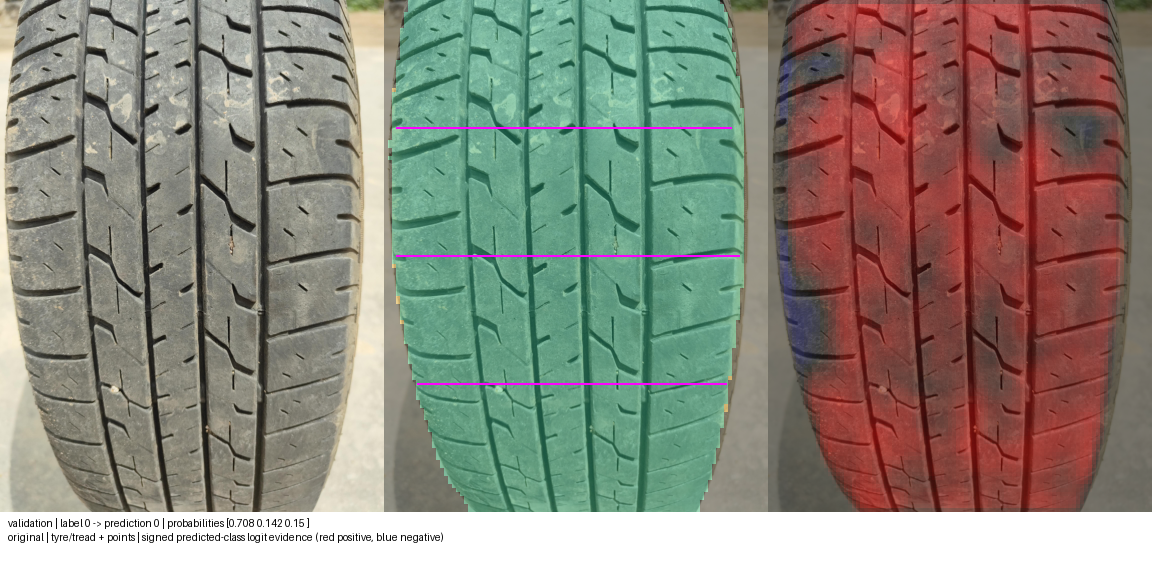

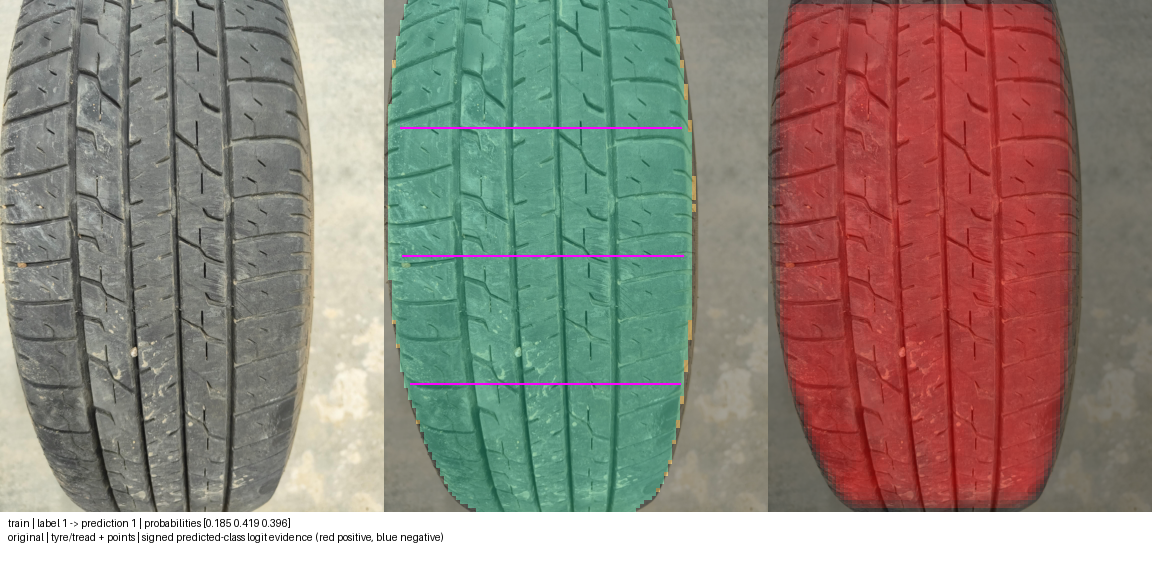

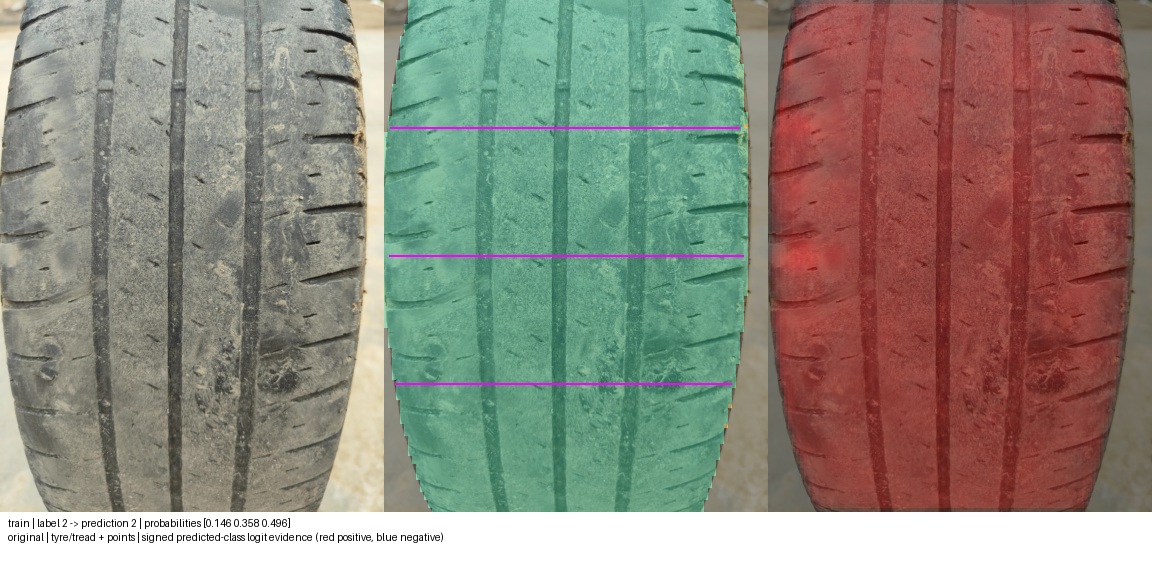

Download: /kaggle/working/TREAD_ONE_Results.zip
Full training state/traces and raw test outputs are also in the verified HF seed bundles.


In [10]:
from IPython.display import display, Image
report = json.loads((WORK/'report/REPORT.json').read_text())
print('Status:', report['status'])
print('Validation-selected export:', report['export_selection'])
print(json.dumps(report['summary'], indent=2))
for path in sorted((WORK/'report/gallery').glob('*.png')):
    display(Image(filename=str(path)))
import zipfile
target = Path('/kaggle/working/TREAD_ONE_Results.zip')
with zipfile.ZipFile(target, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in (WORK/'report').rglob('*'):
        if path.is_file():
            archive.write(path, 'report/'+str(path.relative_to(WORK/'report')))
    for name in ('CONTRACT.json', 'OVERLAY.json', 'ENVIRONMENT.json', 'LAST_REMOTE.json', 'DATA_PREFLIGHT.json'):
        archive.write(WORK/name, name)
print('Download:', target)
print('Full training state/traces and raw test outputs are also in the verified HF seed bundles.')
